<a href="https://colab.research.google.com/github/giovanardo/DATA201-labs/blob/main/Assignments/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Homework: Decision Trees

The Carseats dataset contains information about child car seat sales at 400 stores, including product prices, advertising budgets, store locations, and sales.

**Goal:** Build and evaluate a decision tree, then explore how tree depth affects overfitting.

We want to predict whether a store has **High Sales** or **Low Sales.**

Define:
* High Sales = 1 if Sales > 8
* Low Sales = 0 if Sales <= 8

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

#plt.rcParams['figure.dpi'] = 100

## Part 1: Build a Classification Tree

1. Load the Carseats dataset and create the binary target HighSales. (copy the code from
the lab)
2. Encode categorical predictors.
3. Split the data into 70% training and 30% test sets.
4. Train a DecisionTreeClassifier with max_depth=3.
5. Plot the tree and report training and test accuracy.

In [3]:
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [4]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [6]:
# One-hot encode the three text columns using pd this time!
X = pd.get_dummies(carseats.drop(columns='HighSales'), columns=['ShelveLoc', 'Urban', 'US']).astype(int)
y = carseats['HighSales']

# Hold out 30% of patients for testing. stratify keeps the class mix similar in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

#you can check your sets (X_train, X_test,...)
X_train.head()

(280, 14) (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
69,127,59,0,339,99,65,12,0,0,1,0,1,1,0
273,116,106,8,244,86,58,12,0,0,1,0,1,0,1
226,119,33,0,245,122,56,14,0,1,0,0,1,1,0
305,115,29,26,394,132,33,13,0,0,1,0,1,0,1
92,114,113,0,97,125,29,12,0,0,1,0,1,1,0


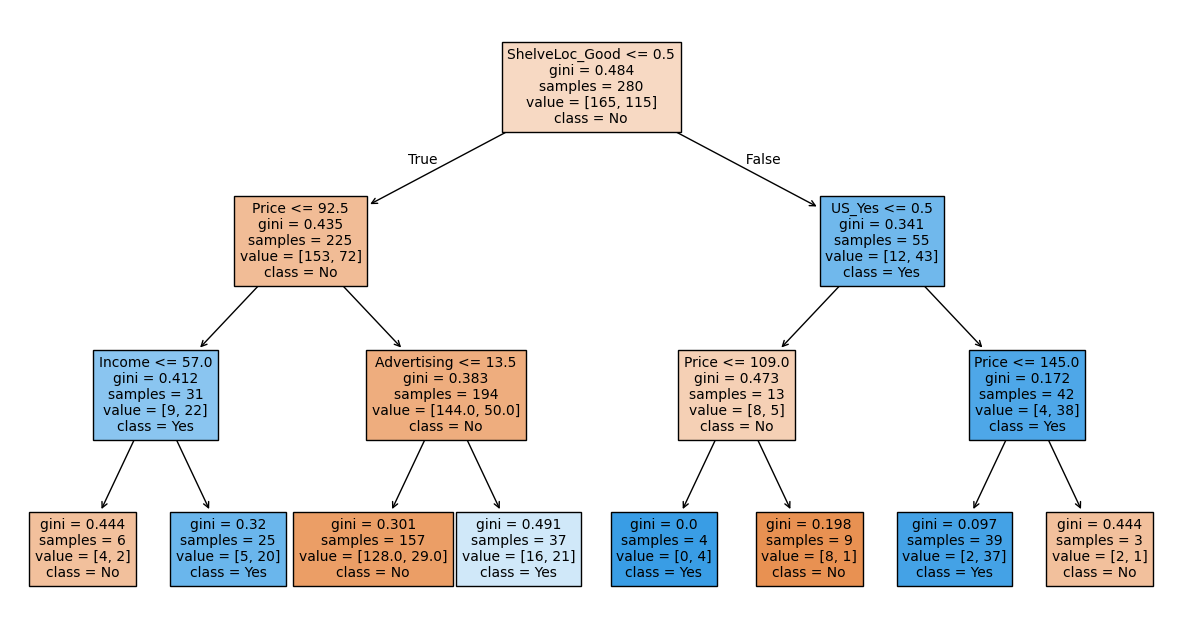

Train accuracy: 0.8
Test accuracy:  0.8


In [7]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(15, 8))

plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'], #here "No" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, #colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

## Part 2: Investigate Overfitting
1. Train decision trees with max_depth values from 1 to 10.
2. Use 5-fold cross-validation on the training data to calculate mean accuracy for each
depth.
3. Create a graph showing tree depth versus cross-validation accuracy.
4. Identify the best depth based on cross-validation.
5. Train a final tree using that depth and evaluate it on the test set.

In [41]:
depths = range(1, 11)
cv_acc = []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    scores = cross_val_score(m, X_train, y_train, cv=5)         #TRAINING data only
    cv_acc.append(scores.mean())

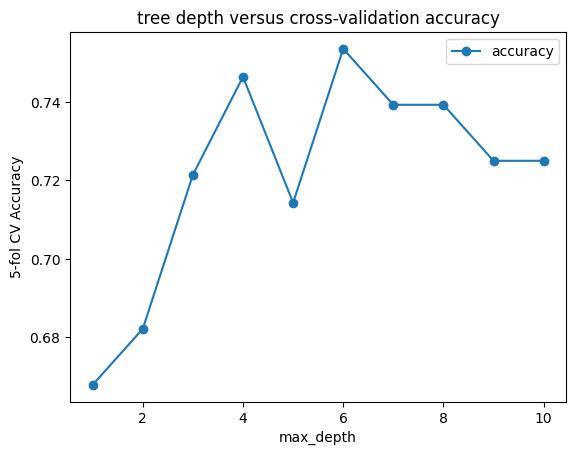

In [44]:
plt.plot(depths, cv_acc, marker='o', label = 'accuracy')
plt.xlabel('max_depth'); plt.ylabel('5-fold CV Accuracy'); plt.legend()
plt.title('tree depth versus cross-validation accuracy')
plt.show()

In [49]:
best_d = list(depths)[int(np.argmax(cv_acc))]
best_tree = DecisionTreeClassifier(max_depth=best_d, random_state=0).fit(X_train, y_train)
best_cv = cv_acc[int(np.argmax(cv_acc))]

print('Best depth:', best_d)
print('Best CV:', round(best_cv, 3))
print('Test accuracy:', round(best_tree.score(X_test, y_test), 3))

Best depth: 6
Best CV: 0.754
Test accuracy: 0.725


## Part 3: Answer the Following Questions
1. Interpreting the tree: Which predictor was selected for the first split (root)? What does
this split tell us about sales?

> The first split was ShelveLoc_Good <= 0.5. The first split contains all the train data and is based on the importance by weighted gini (purity), the tree looks for the best predictor top-down. That means that the good shelf location will have higher sales

2. Choosing tree depth: According to your cross-validation graph, which depth performed
best? Why should we use cross-validation rather than test accuracy to choose the depth?

> The best depth was 6. The cross-validation method tries every combination and score each tree with n-fold that we choose ONLY on the train set avoiding bias results.

3. Overfitting: Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph

> No. as depth reaches 6, the best CV accuracy was found and if the tree kept growing the accuracy decrease. That happens because if the tree grows to the fullest it will start overfit and learn noises.

## Wrap-up questions
Answer in your own words in a text cell.

What does a leaf predict in a classification tree? In a regression tree?

> Classification: most repeated value; classifies based on the mode. Regression: the average from the training set

Why did the full tree reach 100% training accuracy but do worse on the test set?

> The full tree overfits; start learning the noise as memorizes the training set

Give two ways to limit tree complexity. Which one did cross-validation help you tune?

> max_dept and min_sample_leaf. max_dept

Why do we not need to scale features before fitting a tree?

> The tree does not care about the scaling because it compares the features to a threshold

A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

> The importance of the feature has no direction, a low score is not always useless feature. For example, in the heart disease data "Age" might carry the same information as another feature that already has a split with lower gini (reduction in impurity).

Name one strength and one weakness of a single decision tree that you saw in this lab.

> Strenght: Is a simpler model and easy to interpreter the general idea. Because the program makes the decision where the split will happen, the tree decision does not see the full picture.